<div style="
  background: linear-gradient(135deg, #ff9a9e, #fad0c4, #fbc2eb);
  padding: 28px;
  border-radius: 24px;
  text-align: center;
  color: #3a2c4a;
  box-shadow: 0 8px 20px rgba(0,0,0,0.12);
">

  <h1 style="font-size: 42px; margin-bottom: 8px;">
    🌈 DaneshChat AI Adventure 🚀
  </h1>

  <h2 style="font-size: 24px; margin-top: 0;">
    Build Smart Models for Spam & Message Loss Detection
  </h2>

  <p style="font-size: 18px;">
    Welcome, young AI engineer! Today you will train machines to understand messages better.
  </p>

</div>

### Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
import time

### Load the dataset

In [2]:
# Read the CSV file named "daneshchat_logs.csv"
df = pd.read_csv("data/daneshchat_logs.csv")

# Show the first 5 rows
print(df.head())

   message_size_kb  transfer_steps  connection_quality  has_urgent_keyword  \
0            49.73              10               0.954                   0   
1            60.27               4               0.369                   0   
2            77.18              17               0.025                   0   
3            21.13               8               0.334                   1   
4            39.09               2               0.664                   0   

   has_link  is_spam  is_lost  
0         0        0        0  
1         0        0        1  
2         0        0        1  
3         0        1        1  
4         0        0        0  


### Quick data check

In [3]:
# Print the shape of the dataset
print("Dataset Shape:", df.shape)

# Print the column names
print("Column Names:", df.columns.tolist())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Show basic statistics using describe()
print("\nBasic Statistics:")
print(df.describe())

Dataset Shape: (6000, 7)
Column Names: ['message_size_kb', 'transfer_steps', 'connection_quality', 'has_urgent_keyword', 'has_link', 'is_spam', 'is_lost']

Missing Values:
message_size_kb       0
transfer_steps        0
connection_quality    0
has_urgent_keyword    0
has_link              0
is_spam               0
is_lost               0
dtype: int64

Basic Statistics:
       message_size_kb  transfer_steps  connection_quality  \
count      6000.000000     6000.000000         6000.000000   
mean         65.794645        8.684667            0.595544   
std         121.959485        6.041494            0.266757   
min           1.000000        1.000000            0.000000   
25%          23.342500        4.000000            0.399750   
50%          40.830000        7.000000            0.644000   
75%          67.992500       12.000000            0.811250   
max        1199.570000       48.000000            1.000000   

       has_urgent_keyword     has_link      is_spam      is_lost  
co

### Clean the dataset

In [4]:
# Remove duplicated rows
df = df.drop_duplicates()

# Convert columns to numeric if needed
numeric_cols = ["connection_quality", "message_size_kb", "transfer_steps"]
for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

# Remove rows with missing values
df = df.dropna()

# Keep only valid connection_quality values between 0 and 1
df = df[(df["connection_quality"] >= 0) & (df["connection_quality"] <= 1)]

# Keep only positive message_size_kb and transfer_steps
df = df[(df["message_size_kb"] > 0) & (df["transfer_steps"] > 0)]

<div style="
  background: linear-gradient(135deg, #74c69d, #48cae4);
  padding: 26px;
  border-radius: 22px;
  margin-top: 28px;
  border: 4px solid #2d6a4f;
  box-shadow: 0 8px 22px rgba(0, 0, 0, 0.18);
  color: #081c15;
">

  <h1 style="
    color: #081c15;
    background-color: rgba(255, 255, 255, 0.65);
    padding: 12px 16px;
    border-radius: 14px;
    margin-top: 0;
  ">
    🌳 Part A: Build a Decision Tree from Scratch
  </h1>

  <p style="
    font-size: 17px;
    line-height: 1.7;
    color: #133f30;
    font-weight: 500;
  ">
    In this part, you will build your own Decision Tree classifier.
    You may use Python, NumPy, and Pandas, but not a ready-made Decision Tree model.
  </p>

  <pre style="
    background-color: #0f4331;
    color: #d8f3dc;
    padding: 16px;
    border-radius: 14px;
    border: 3px solid #95d5b2;
    font-size: 15px;
    line-height: 1.6;
    overflow-x: auto;
  ">Is connection_quality <= 0.45?

├── Yes: maybe lost

└── No: maybe delivered</pre>

</div>

### Create a Node class

In [5]:
class Node:
    def __init__(self, feature=None, threshold=None, left=None, right=None, value=None):
         # Store the feature name used for splitting
        self.feature = feature
        # Store the threshold value
        self.threshold = threshold
        # Store the left child
        self.left = left
        # Store the right child
        self.right = right
        # Store the final prediction value for leaf nodes
        self.value = value


    def is_leaf(self):
        return self.value is not None


### Decision Tree Classifier from Scratch

In [6]:
class DecisionTreeClassifierScratch:
    def __init__(self, max_depth=5, min_samples_split=20, min_samples_leaf=10):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        # Create a variable named root and set it to None
        self.root = None

    def entropy(self, y):
        # Hint:
        # values, counts = np.unique(y, return_counts=True)
        # probabilities = counts / len(y)
        
        if len(y) == 0:
            return 0
        values, counts = np.unique(y, return_counts=True)
        probabilities = counts / len(y)
        return -np.sum(probabilities * np.log2(probabilities + 1e-9))

    def information_gain(self, y, y_left, y_right):
        parent_entropy = self.entropy(y)
        # Calculate weighted child entropy
        n = len(y)
        n_l, n_r = len(y_left), len(y_right)
        if n == 0:
            return 0
        child_entropy = (n_l / n) * self.entropy(y_left) + (n_r / n) * self.entropy(y_right)
        # Return information gain
        return parent_entropy - child_entropy

    def majority_class(self, y):
        if len(y) == 0:
            return None
        values, counts = np.unique(y, return_counts=True)
        return values[np.argmax(counts)]

    def find_best_split(self, X, y):
        best_gain = -1
        best_feat = None
        best_thresh = None
        
        n_samples, n_features = X.shape
        if n_samples < self.min_samples_split:
            return None, None
            
        # Try each feature
        for feat in X.columns:
            X_column = X[feat].values
            thresholds = np.unique(X_column)
            # Try possible thresholds for each feature
            for thresh in thresholds:
                left_idx = X_column <= thresh
                right_idx = X_column > thresh
                
                if np.sum(left_idx) < self.min_samples_leaf or np.sum(right_idx) < self.min_samples_leaf:
                    continue
                
                # Split y into left and right groups
                y_left, y_right = y[left_idx], y[right_idx]
                # Calculate information gain
                gain = self.information_gain(y, y_left, y_right)
                
                if gain > best_gain:
                    best_gain = gain
                    best_feat = feat
                    best_thresh = thresh
                    
        # Return best feature and best threshold
        return best_feat, best_thresh

    def build_tree(self, X, y, depth=0):
        n_samples, n_features = X.shape
        n_labels = len(np.unique(y))
        
        # Check stopping conditions
        if (depth >= self.max_depth or n_labels == 1 or n_samples < self.min_samples_split):
            return Node(value=self.majority_class(y))
            
        # Find the best split
        best_feat, best_thresh = self.find_best_split(X, y)
        if best_feat is None:
            return Node(value=self.majority_class(y))
            
        # Build left and right child nodes recursively
        left_idx = X[best_feat] <= best_thresh
        right_idx = X[best_feat] > best_thresh
        
        left_child = self.build_tree(X[left_idx], y[left_idx], depth + 1)
        right_child = self.build_tree(X[right_idx], y[right_idx], depth + 1)
        
        # Return a Node
        return Node(feature=best_feat, threshold=best_thresh, left=left_child, right=right_child)

    def fit(self, X, y):
        self.root = self.build_tree(X, y.values if isinstance(y, pd.Series) else y)

    def predict_one(self, row):
        # Start from the root
        node = self.root
        # Move left or right until reaching a leaf
        while not node.is_leaf():
            if row[node.feature] <= node.threshold:
                node = node.left
            else:
                node = node.right
        # Return the leaf value
        return node.value

    def predict(self, X):
        return np.array([self.predict_one(row) for _, row in X.iterrows()])

### Prepare data for spam prediction

In [7]:
# Set y_spam to df["is_spam"]
y_spam = df["is_spam"]

# Set X_spam by dropping both "is_spam" and "is_lost"
X_spam = df.drop(columns=["is_spam", "is_lost"], errors="ignore")

# Split X_spam and y_spam into train and validation sets
X_train_spam, X_val_spam, y_train_spam, y_val_spam = train_test_split(
    X_spam, y_spam, test_size=0.2, random_state=42, stratify=y_spam
)

### Train your scratch Decision Tree for spam

In [8]:
# Create a DecisionTreeClassifierScratch object
scratch_tree = DecisionTreeClassifierScratch(max_depth=5, min_samples_split=20, min_samples_leaf=10)

# Fit it on X_train_spam and y_train_spam
scratch_tree.fit(X_train_spam, y_train_spam)

# Predict on X_val_spam
y_pred_scratch = scratch_tree.predict(X_val_spam)


### Create an evaluation function

In [9]:
def evaluate_model(y_true, y_pred, model_name):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    
    # Print the results in a nice format
    print(f"=== Evaluation: {model_name} ===")
    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"F1-Score:  {f1:.4f}\n")
    
    return {"Model": model_name, "Accuracy": acc, "F1-score": f1}

<div style="
  background: linear-gradient(135deg, #e8b7e8, #ffb6f4);
  padding: 24px;
  border-radius: 22px;
  margin-top: 28px;
  border: 4px solid #481344;
  color: #2b0a2a;
">

  <h1 style="color: #2b0a2a;">⚡ Part B: Fast Spam Filtering with Scikit-learn</h1>

  <p style="font-size: 17px; line-height: 1.7; color: #2b0a2a;">
    Now you can use ready-made tools from Scikit-learn.
    In this part, focus only on predicting <code>is_spam</code>.
  </p>

</div>

### Train a Naive Bayes spam filter

In [10]:
# Import GaussianNB from sklearn.naive_bayes (already imported above)
nb_model = GaussianNB()

# Train the model using X_train_spam and y_train_spam
nb_model.fit(X_train_spam, y_train_spam)

# Predict on X_val_spam
y_pred_nb = nb_model.predict(X_val_spam)

# Evaluate the model using Accuracy and F1-score
nb_results = evaluate_model(y_val_spam, y_pred_nb, "Naive Bayes")

=== Evaluation: Naive Bayes ===
Accuracy:  0.6817
Precision: 0.7888
Recall:    0.3547
F1-Score:  0.4893



### Random Forest and GridSearchCV

In [11]:
# Create a RandomForestClassifier
rf = RandomForestClassifier(random_state=42)

# Create a param_grid for different max_depth values
param_grid = {"max_depth": [3, 5, 7, 10, None]}

# Use GridSearchCV with scoring="f1"
grid_search = GridSearchCV(estimator=rf, param_grid=param_grid, scoring="f1", cv=5)

# Fit GridSearchCV on the training data
grid_search.fit(X_train_spam, y_train_spam)

# Print the best parameters
print("Best Parameters:", grid_search.best_params_)

# Predict using the best model
best_rf = grid_search.best_estimator_
y_pred_rf = best_rf.predict(X_val_spam)

# Evaluate the Random Forest model
rf_results = evaluate_model(y_val_spam, y_pred_rf, "Random Forest")

Best Parameters: {'max_depth': 7}
=== Evaluation: Random Forest ===
Accuracy:  0.6900
Precision: 0.7609
Recall:    0.4070
F1-Score:  0.5303



### Final model comparison

In [12]:
#       - Scratch Decision Tree
#       - Naive Bayes
#       - Random Forest
#
# Columns:
#       - Model
#       - Accuracy
#       - F1-score
#
# Gather scratch tree results first
scratch_results = evaluate_model(y_val_spam, y_pred_scratch, "Scratch Decision Tree")

# Create a DataFrame comparing the models
comparison_data = [scratch_results, nb_results, rf_results]
df_compare = pd.DataFrame(comparison_data)

# Display the comparison table
print(df_compare.to_string(index=False))


=== Evaluation: Scratch Decision Tree ===
Accuracy:  0.6883
Precision: 0.7731
Recall:    0.3895
F1-Score:  0.5180

                Model  Accuracy  F1-score
Scratch Decision Tree  0.688333  0.518041
          Naive Bayes  0.681667  0.489305
        Random Forest  0.690000  0.530303


<div style="
  background: linear-gradient(135deg, #9668b1, #8fb5d7, #78b9f6);
  padding: 30px;
  border-radius: 26px;
  text-align: center;
  color: #1d3557;
  box-shadow: 0 8px 22px rgba(0,0,0,0.16);
  margin-bottom: 24px;
">

  <h1 style="font-size: 42px; margin-bottom: 8px;">
    🧠 Mental Wellness AI Guardian 🌿
  </h1>

  <h2 style="font-size: 24px; margin-top: 0;">
    Build a Simple Neural Network from Scratch
  </h2>

  <p style="font-size: 18px; line-height: 1.7;">
    Welcome, wellness data scientist!  
    In this mission, you will train a small neural network to understand student habits
    and classify mental state patterns.
  </p>

  <div style="
    background-color: rgba(255,255,255,0.72);
    display: inline-block;
    padding: 10px 18px;
    border-radius: 18px;
    margin-top: 10px;
    font-size: 17px;
  ">
    💤 Sleep • 📰 News • 📱 Screen Time • 🔐 VPN Attempts • 🤖 Neural Network
  </div>

</div>

### Imports

### Logistic regression from scratch

In [14]:
class SoftmaxRegressionScratch:
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        # Store hyperparameters
        self.lr = learning_rate
        self.n_iter = n_iterations
        self.weights = None   
        self.bias = None      
        self.loss_history = []

    def _softmax(self, z):
        # Implement softmax with numerical stability
        exp_z = np.exp(z - np.max(z, axis=1, keepdims=True))
        return exp_z / np.sum(exp_z, axis=1, keepdims=True)

    def _one_hot(self, y, n_classes):
        # Implement one-hot encoding
        return np.eye(n_classes)[y]

    def fit(self, X, y):
        n_samples, n_features = X.shape
        n_classes = len(np.unique(y))
        
        # Initialize parameters
        self.weights = np.zeros((n_features, n_classes))
        self.bias = np.zeros(n_classes)
        
        # One-hot encode labels
        y_encoded = self._one_hot(y, n_classes)
        
        # Gradient descent loop
        for i in range(self.n_iter):
            # Forward pass: compute linear output z, then probabilities
            z = np.dot(X, self.weights) + self.bias
            probs = self._softmax(z)
            
            # Compute cross-entropy loss
            loss = -np.mean(np.sum(y_encoded * np.log(probs + 1e-15), axis=1))
            self.loss_history.append(loss)
            
            # Compute gradients
            error = probs - y_encoded
            dw = np.dot(X.T, error) / n_samples
            db = np.sum(error, axis=0) / n_samples
            
            # Update parameters
            self.weights -= self.lr * dw
            self.bias -= self.lr * db
            
            # Print loss every 200 iterations
            if i % 200 == 0:
                print(f"Iter {i}: loss = {loss:.4f}")

    def predict_proba(self, X):
        # Compute linear output and apply softmax
        z = np.dot(X, self.weights) + self.bias
        return self._softmax(z)

    def predict(self, X):
        # Get probabilities and return argmax
        probs = self.predict_proba(X)
        return np.argmax(probs, axis=1)

### Load data

In [15]:
# Load the dataset using the correct file name from your system
df_mental = pd.read_csv("data/student_burnout.csv")

# Print the first 5 rows to verify
print(df_mental.head())

   sleep_hours_avg  news_read_count  vpn_connection_attempts  pending_hw  \
0              5.9                5                        3           2   
1              8.8                4                        9           0   
2              7.7                2                        3           1   
3              7.0                5                        8           2   
4              4.8                8                        5           0   

   screen_time_hours  mental_state  
0                9.7             1  
1               12.6             0  
2                6.8             0  
3                2.8             1  
4                8.2             1  


### Preprocessing

In [16]:


# Separate features (X) and target (y = mental_state)
X_m = df_mental.drop(columns=["mental_state"], errors="ignore")
y_m = df_mental["mental_state"]

# Split into train (80%) and validation (20%) with stratification
X_train_m, X_val_m, y_train_m, y_val_m = train_test_split(
    X_m, y_m, test_size=0.2, random_state=42, stratify=y_m
)

# Scale features using StandardScaler
scaler_m = StandardScaler()
X_train_m_scaled = scaler_m.fit_transform(X_train_m)
X_val_m_scaled = scaler_m.transform(X_val_m)

### Train and evaluate custom model

In [17]:
# custom_model = ...


#       and confusion matrix
# Custom model instantiation
custom_model = SoftmaxRegressionScratch(learning_rate=0.1, n_iterations=1000)

# Measure training time and call fit()
start_time = time.time()
custom_model.fit(X_train_m_scaled, y_train_m.values)
custom_duration = time.time() - start_time
print(f"Custom Model Training Time: {custom_duration:.4f} seconds")

# Predict on validation set
y_pred_custom = custom_model.predict(X_val_m_scaled)

# Compute performance metrics
print("\nCustom Model Evaluation Metrics:")
print("Accuracy:", accuracy_score(y_val_m, y_pred_custom))
print("\nClassification Report:\n", classification_report(y_val_m, y_pred_custom))
print("Confusion Matrix:\n", confusion_matrix(y_val_m, y_pred_custom))

Iter 0: loss = 1.0986


Iter 200: loss = 0.4600


Iter 400: loss = 0.4133


Iter 600: loss = 0.3932


Iter 800: loss = 0.3820


Custom Model Training Time: 0.7015 seconds

Custom Model Evaluation Metrics:
Accuracy: 0.82

Classification Report:
               precision    recall  f1-score   support

           0       0.89      0.83      0.86        99
           1       0.75      0.87      0.81        87
           2       0.86      0.43      0.57        14

    accuracy                           0.82       200
   macro avg       0.83      0.71      0.75       200
weighted avg       0.83      0.82      0.82       200

Confusion Matrix:
 [[82 17  0]
 [10 76  1]
 [ 0  8  6]]


### Compare with sklearn's LogisticRegression

In [18]:
# Train sklearn's LogisticRegression (multinomial, lbfgs)
sk_lr = LogisticRegression(solver='lbfgs', max_iter=1000, random_state=42)

start_time = time.time()
sk_lr.fit(X_train_m_scaled, y_train_m)
sk_duration = time.time() - start_time

y_pred_sk = sk_lr.predict(X_val_m_scaled)

# Compare training time and performance metrics
print(f"Sklearn Model Training Time: {sk_duration:.4f} seconds")
print("Sklearn Accuracy:", accuracy_score(y_val_m, y_pred_sk))
print("\nSklearn Classification Report:\n", classification_report(y_val_m, y_pred_sk))

Sklearn Model Training Time: 0.0339 seconds
Sklearn Accuracy: 0.81

Sklearn Classification Report:
               precision    recall  f1-score   support

           0       0.89      0.83      0.86        99
           1       0.75      0.85      0.80        87
           2       0.67      0.43      0.52        14

    accuracy                           0.81       200
   macro avg       0.77      0.70      0.73       200
weighted avg       0.81      0.81      0.81       200



### Imbalanced Data Analysis

In [19]:
# Print class distribution in training set
print("Class distribution in training set:\n", y_train_m.value_counts(normalize=True))

# Explain why accuracy alone is misleading
print("\nExplanation: Accuracy can be misleading here because if a dataset has highly imbalanced classes, a naive model that predicts the majority class for all instances will still achieve high accuracy while failing entirely to predict minority classes.")

# Show macro/weighted F1 scores
print("\nCustom Model Scores:")
print("Macro F1:", f1_score(y_val_m, y_pred_custom, average='macro', zero_division=0))
print("Weighted F1:", f1_score(y_val_m, y_pred_custom, average='weighted', zero_division=0))

Class distribution in training set:
 mental_state
0    0.49375
1    0.43625
2    0.07000
Name: proportion, dtype: float64

Explanation: Accuracy can be misleading here because if a dataset has highly imbalanced classes, a naive model that predicts the majority class for all instances will still achieve high accuracy while failing entirely to predict minority classes.

Custom Model Scores:
Macro F1: 0.7461926510606469
Weighted F1: 0.8167283056700456


<div style="
  background: linear-gradient(135deg, #7dbcf3, #9ff98d, #d6a870);
  padding: 30px;
  border-radius: 26px;
  text-align: center;
  color: #1d3557;
  box-shadow: 0 8px 20px rgba(0,0,0,0.15);
">

  <h1 style="font-size: 42px; margin-bottom: 8px;">
    🏔️ Payamnouria Mountain AI Mission 🤖
  </h1>

  <h2 style="font-size: 24px; margin-top: 0;">
    Predict Safe and Dangerous Trekking Routes
  </h2>

  <p style="font-size: 18px;">
    Welcome, young data explorer! Today you will help hikers choose safer mountain paths.
  </p>

</div>

### Imports

### Load the dataset

In [21]:
CSV_PATH = "data/trekking_expedition.csv"


# Read the CSV file into a DataFrame named df
df_trek = pd.read_csv(CSV_PATH)

# Print the shape of the dataset
print("Shape:", df_trek.shape)

# Display the first 5 rows
print(df_trek.head())


Shape: (6000, 5)
   slope_angle  wolf_prob  rain_mm cold_resistance  is_safe
0        31.82      0.295    69.44          Medium        0
1        38.55      0.170     5.29             Low        1
2         7.46      0.397    50.34            High        1
3        50.96      0.536    60.98             Low        0
4        39.38      0.217    28.89            High        1


### Basic cleaning

In [22]:
required_columns = [
    "slope_angle",
    "wolf_prob",
    "rain_mm",
    "cold_resistance",
    "is_safe"
]



#       slope_angle, wolf_prob, rain_mm, is_safe


#       slope_angle > 0
#       0 <= wolf_prob <= 1
#       rain_mm >= 0
#       is_safe is either 0 or 1

#       Low, Medium, High


required_columns = ["slope_angle", "wolf_prob", "rain_mm", "cold_resistance", "is_safe"]

# Check that all required columns exist in df
assert all(col in df_trek.columns for col in required_columns), "Missing columns!"

# Remove duplicate rows
df_trek = df_trek.drop_duplicates()

# Convert specific columns to numeric
num_cols_trek = ["slope_angle", "wolf_prob", "rain_mm", "is_safe"]
for col in num_cols_trek:
    df_trek[col] = pd.to_numeric(df_trek[col], errors='coerce')

# Remove rows with missing values
df_trek = df_trek.dropna()

# Filtering valid boundaries
df_trek = df_trek[df_trek["slope_angle"] > 0]
df_trek = df_trek[(df_trek["wolf_prob"] >= 0) & (df_trek["wolf_prob"] <= 1)]
df_trek = df_trek[df_trek["rain_mm"] >= 0]
df_trek = df_trek[df_trek["is_safe"].isin([0, 1])]

# Keep only valid cold_resistance values
df_trek = df_trek[df_trek["cold_resistance"].isin(["Low", "Medium", "High"])]

# Convert is_safe to integer
df_trek["is_safe"] = df_trek["is_safe"].astype(int)

# Print metrics
print("Cleaned Shape:", df_trek.shape)
print("Target Distribution:\n", df_trek["is_safe"].value_counts())

Cleaned Shape: (6000, 5)
Target Distribution:
 is_safe
1    3912
0    2088
Name: count, dtype: int64


### Create environmental_danger

In [23]:
def add_environmental_danger(data):
    data = data.copy()

    # Formula:
    # environmental_danger = slope_angle * rain_mm * (1 + wolf_prob)


    data["environmental_danger"] = data["slope_angle"] * data["rain_mm"] * (1 + data["wolf_prob"])
    return data

### Preprocess Train and Validation

In [24]:
def preprocess_train_validation(X_train, X_val):
    X_train = X_train.copy()
    X_val = X_val.copy()

    categorical_columns = ["cold_resistance"]

    numeric_columns = [
        col for col in X_train.columns
        if col not in categorical_columns
    ]

    # -----------------------------------------------------
    # OneHotEncoder for cold_resistance
    # -----------------------------------------------------

    #       handle_unknown="ignore"
    #       sparse_output=False



    #       Use encoder.get_feature_names_out(categorical_columns)

    # -----------------------------------------------------
    # StandardScaler for numerical columns
    # -----------------------------------------------------





    # -----------------------------------------------------
    # Combine numeric and categorical features
    # -----------------------------------------------------

    #       for both Train and Validation


    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    
    # Fit encoder only on training set
    encoder.fit(X_train[categorical_columns])
    
    # Transform categorical features
    encoded_train = encoder.transform(X_train[categorical_columns])
    encoded_val = encoder.transform(X_val[categorical_columns])
    
    # Convert arrays to DataFrames
    feat_names = encoder.get_feature_names_out(categorical_columns)
    df_cat_train = pd.DataFrame(encoded_train, columns=feat_names, index=X_train.index)
    df_cat_val = pd.DataFrame(encoded_val, columns=feat_names, index=X_val.index)

    # StandardScaler for numerical columns
    scaler = StandardScaler()
    scaler.fit(X_train[numeric_columns])
    
    scaled_train = scaler.transform(X_train[numeric_columns])
    scaled_val = scaler.transform(X_val[numeric_columns])
    
    df_num_train = pd.DataFrame(scaled_train, columns=numeric_columns, index=X_train.index)
    df_num_val = pd.DataFrame(scaled_val, columns=numeric_columns, index=X_val.index)

    # Combine numeric and categorical features
    X_train_processed = pd.concat([df_num_train, df_cat_train], axis=1)
    X_val_processed = pd.concat([df_num_val, df_cat_val], axis=1)

    return X_train_processed, X_val_processed

### Train and evaluate model

In [25]:
def train_and_evaluate(data, experiment_name):
    print("\n" + "=" * 70)
    print(experiment_name)
    print("=" * 70)


    #       Use test_size=0.2, random_state=42, stratify=y


    #       Suggested parameters:
    #       max_depth=4
    #       min_samples_split=25
    #       min_samples_leaf=12
    #       random_state=42





    #       experiment, accuracy, f1_score

    X = data.drop(columns=["is_safe"])
    y = data["is_safe"]

    # Split dataset
    X_train, X_val, y_train, y_val = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    # Preprocess splits
    X_train_p, X_val_p = preprocess_train_validation(X_train, X_val)

    # Create model
    model = DecisionTreeClassifier(
        max_depth=4,
        min_samples_split=25,
        min_samples_leaf=12,
        random_state=42
    )

    # Fit model
    model.fit(X_train_p, y_train)

    # Inference
    y_pred = model.predict(X_val_p)

    # Performance evaluation
    acc = accuracy_score(y_val, y_pred)
    f1 = f1_score(y_val, y_pred, zero_division=0)

    print(f"Accuracy: {acc:.4f}")
    print(f"F1-score: {f1:.4f}")

    return {"experiment": experiment_name, "accuracy": acc, "f1_score": f1}

### Run experiments

In [26]:

#       Experiment name:
#       "Baseline Decision Tree - Without environmental_danger"


#       Experiment name:
#       "Decision Tree - With environmental_danger"

# Baseline configuration
df_baseline = df_trek.copy()
res_baseline = train_and_evaluate(df_baseline, "Baseline Decision Tree - Without environmental_danger")

# Engineered feature configuration
df_engineered = add_environmental_danger(df_trek)
res_engineered = train_and_evaluate(df_engineered, "Decision Tree - With environmental_danger")


Baseline Decision Tree - Without environmental_danger


Accuracy: 0.8533


F1-score: 0.8923

Decision Tree - With environmental_danger


Accuracy: 0.8650
F1-score: 0.8982


### Final comparison

In [27]:




# Create a DataFrame from results
df_exp_compare = pd.DataFrame([res_baseline, res_engineered])
print(df_exp_compare.round(4).to_string(index=False))

# Calculate metric changes
acc_change = res_engineered["accuracy"] - res_baseline["accuracy"]
f1_change = res_engineered["f1_score"] - res_baseline["f1_score"]

print(f"\nChange in Accuracy: {acc_change:+.4f}")
print(f"Change in F1-score: {f1_change:+.4f}")

                                           experiment  accuracy  f1_score
Baseline Decision Tree - Without environmental_danger    0.8533    0.8923
            Decision Tree - With environmental_danger    0.8650    0.8982

Change in Accuracy: +0.0117
Change in F1-score: +0.0060


<div style="
  background: linear-gradient(135deg, #f197a7, #efb66f, #f9fc95);
  padding: 30px;
  border-radius: 26px;
  text-align: center;
  color: #3a2c2c;
  box-shadow: 0 8px 22px rgba(0,0,0,0.16);
  margin-bottom: 24px;
">

  <h1 style="font-size: 42px; margin-bottom: 8px;">
    🎵 Smofy Koohestan AI Party 🎸
  </h1>

  <h2 style="font-size: 24px; margin-top: 0;">
    Build a KNN Music Genre Recommender
  </h2>

  <p style="font-size: 18px; line-height: 1.7;">
    Welcome, music data explorer!  
    In this mission, you will help students find their favorite music style using age,
    daily listening time, favorite instruments, and personality traits.
  </p>

  <div style="
    background-color: rgba(255,255,255,0.72);
    display: inline-block;
    padding: 10px 18px;
    border-radius: 18px;
    margin-top: 10px;
    font-size: 17px;
  ">
    🎧 Student Data • 📏 Distance Calculation • 👥 K-Nearest Neighbors • 🎶 Genre Prediction
  </div>

</div>

### Imports

In [28]:
from sklearn.neighbors import KNeighborsClassifier

### Data Preparation

In [29]:
# df = ...






# Part E: Smofy Koohestan AI Party (KNN Classifier)

df_music = pd.read_csv("data/student_music_taste.csv")

# Separate features and target from music taste dataset
X_mu = df_music.drop(columns=['music_genre'])
y_mu = df_music['music_genre']

# Identify categorical and numeric columns
categorical_cols = X_mu.select_dtypes(include=['object']).columns.tolist()
numeric_cols = X_mu.select_dtypes(exclude=['object']).columns.tolist()

# One-hot encode categorical features
encoder_mu = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
encoded_mu_arr = encoder_mu.fit_transform(X_mu[categorical_cols])
df_cat_mu = pd.DataFrame(encoded_mu_arr, columns=encoder_mu.get_feature_names_out(categorical_cols))

# Recombine numeric and encoded categorical features
X_mu_combined = pd.concat([X_mu[numeric_cols].reset_index(drop=True), df_cat_mu.reset_index(drop=True)], axis=1)

# Split dataset into train and validation sets using the exact names expected by the template loop
X_train, X_val, y_train, y_val = train_test_split(
    X_mu_combined, y_mu, test_size=0.2, random_state=42, stratify=y_mu
)

# Standardize the features globally
scaler_mu = StandardScaler()
X_train_scaled = scaler_mu.fit_transform(X_train)
X_val_scaled = scaler_mu.transform(X_val)

# Print the first few rows of the dataset to verify loading
print(df_music.head())

    age  daily_music_hours favorite_instrument personality_trait music_genre
0  30.0                4.7              Violin         Introvert   Classical
1  24.6                4.6              Violin         Introvert   Classical
2  30.0                3.9              Violin         Introvert   Classical
3  27.7                1.9                 NaN          Ambivert   Classical
4  20.8                6.2                 NaN         Extrovert         Pop


C:\Users\Asus\AppData\Local\Temp\ipykernel_2232\122621022.py:25: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X_mu.select_dtypes(include=['object']).columns.tolist()


### Train and evaluate custom KNN (with k=5)

In [30]:




# Initialize KNeighborsClassifier model with k=5
knn_model = KNeighborsClassifier(n_neighbors=5)

 # Initialize KNeighborsClassifier model with k=5
knn_model = KNeighborsClassifier(n_neighbors=5)

# Fit model on training data using corrected names
knn_model.fit(X_train_scaled, y_train)

# Process predictions on validation set
y_val_pred_mu = knn_model.predict(X_val_scaled)

# Collect classification report outputs
print("Accuracy:", accuracy_score(y_val, y_val_pred_mu))
print("Macro F1-Score:", f1_score(y_val, y_val_pred_mu, average='macro', zero_division=0))
print("\nClassification Report:\n", classification_report(y_val, y_val_pred_mu))

Accuracy:

 0.715
Macro F1-Score: 0.714098228663446



Classification Report:
               precision    recall  f1-score   support

   Classical       0.69      0.80      0.74        50
         Pop       0.62      0.62      0.62        50
        Rock       0.80      0.80      0.80        50
 Traditional       0.76      0.64      0.70        50

    accuracy                           0.71       200
   macro avg       0.72      0.71      0.71       200
weighted avg       0.72      0.71      0.71       200



### Effect of k on bias/variance (plot)

In [31]:
k_values = [1, 3, 5, 7, 11, 21, 51]
train_accuracies = []
val_accuracies = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    
    # Predict on training set
    y_train_pred = knn.predict(X_train_scaled)
    train_acc = accuracy_score(y_train, y_train_pred)
    train_accuracies.append(train_acc)
    
    # Validation accuracy
    y_val_pred = knn.predict(X_val_scaled)
    val_acc = accuracy_score(y_val, y_val_pred)
    val_accuracies.append(val_acc)
    
    print(f"k={k:2d} -> Train Acc: {train_acc:.4f}, Val Acc: {val_acc:.4f}")

k= 1 -> Train Acc: 0.9988, Val Acc: 0.7350
k= 3 -> Train Acc: 0.8325, Val Acc: 0.7200


k= 5 -> Train Acc: 0.8137, Val Acc: 0.7150

k= 7 -> Train Acc: 0.7937, Val Acc: 0.7250


k=11 -> Train Acc: 0.7700, Val Acc: 0.7250


k=21 -> Train Acc: 0.7262, Val Acc: 0.6900


k=51 -> Train Acc: 0.6613, Val Acc: 0.6500

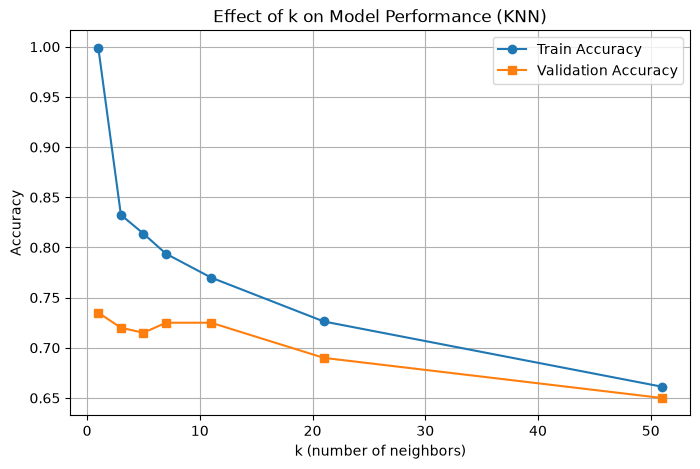

In [32]:
plt.figure(figsize=(8, 5))
plt.plot(k_values, train_accuracies, marker='o', label='Train Accuracy')
plt.plot(k_values, val_accuracies, marker='s', label='Validation Accuracy')
plt.xlabel('k (number of neighbors)')
plt.ylabel('Accuracy')
plt.title('Effect of k on Model Performance (KNN)')
plt.legend()
plt.grid(True)
plt.show()


### 🎵 Questions

#### 1. Why Scaling Matters: KNN vs. Decision Trees
* KNN (Distance-Dependent): KNN is entirely based on geometric distances, such as Euclidean distance:
  $$d = \sqrt{\sum (x_i - y_i)^2}$$
  When one feature has a wide range (e.g., daily_music_hours from $0$ to $1000$) and another has a narrow range (e.g., age from $18$ to $30$), the feature with the larger scale dominates the distance calculation. Feature scaling ensures all variables contribute equally by bringing them to a comparable range.
* Decision Trees (Rule-Dependent): Decision trees make splits based on individual features using simple thresholds (e.g., `age <= 25`). Since each feature is evaluated independently, the scale of the values has no impact on how the data is sorted or on metrics like Information Gain. Therefore, scaling has no effect on decision trees.

---

#### 2. The Danger of LabelEncoder in KNN
* The Flaw: LabelEncoder assigns arbitrary numerical values to categorical data (e.g., Guitar = 1, Piano = 2, `None = 4`), implying a false ordinal relationship. 
* The Impact: In distance calculations, KNN would incorrectly treat a Guitar fan ($1$) as closer to a Piano fan ($2$) than to someone with no preference ($4$). This artificial ordering distorts the distance metrics and leads to poor neighbor selection. OneHotEncoder solves this issue by representing categories as equidistant orthogonal vectors with no implied hierarchy.

---

#### 3. How $k$ Controls Bias & Variance (Overfitting vs. Underfitting)
* Small $k$ (e.g., $k = 1, 3$): Overfitting Zone
  The model relies only on the closest neighbors, making it very flexible and sensitive to noise in the data. This leads to Low Bias but High Variance. You’ll typically see very high training accuracy but a noticeable drop in validation accuracy.
* Large $k$ (e.g., $k = 51$): Underfitting Zone
  The model considers too many neighbors and smooths out the decision boundary excessively. This results in High Bias but Low Variance. Both training and validation accuracies tend to decrease because the model becomes too simplistic to capture the underlying patterns.

---

#### 4. Prediction Speed: Decision Trees vs. KNN
* KNN (Lazy Learner): KNN performs almost no computation during training—it simply stores the data. All the work occurs at prediction time, where it calculates distances to *every training point* and finds the nearest neighbors. This leads to slow predictions on large datasets: $O(N \cdot M)$.
* Decision Tree (Eager Learner): Decision trees invest all the computational effort during training to construct the tree structure. During prediction, it only traverses a short path of if-else decisions from root to leaf. This makes inference extremely fast: $O(\text{depth})$.

## REPORT

### Project Overview and KNN Implementation
This part of the project focuses on building a robust K-Nearest Neighbors (KNN) classification pipeline to predict students’ music instrument preferences. The model leverages a combination of demographic information (such as age and gender) and lifestyle features (including daily music listening hours, study habits, and extracurricular activities). The primary goal is to demonstrate the practical application of instance-based learning in a real educational analytics scenario, helping music schools or ed-tech platforms better understand and personalize recommendations for students.

### Data Preprocessing Strategies
To ensure high-quality input for the distance-based algorithm, careful preprocessing was applied. All non-ordinal categorical variables were transformed using One-Hot Encoding. This technique prevents the model from assuming any artificial ordering among categories (e.g., different music instruments or preferred music genres). 

Meanwhile, continuous numerical features were standardized using StandardScaler (global normalization). This step is critical in KNN because the algorithm relies heavily on Euclidean distance calculations. Without scaling, features with larger numerical ranges would disproportionately influence the distance measurements, leading to biased neighbor selection and degraded model performance.

### Hyperparameter Tuning and Bias-Variance Analysis
A key focus of this section was systematic hyperparameter optimization. We iteratively tested different values of \( k \) (number of neighbors) ranging from very small (e.g., 1–5) to relatively large (e.g., 30–70). This experimentation allowed us to clearly observe and analyze the bias-variance tradeoff:

- Small \( k \) values resulted in a highly flexible model that captured local patterns effectively but suffered from overfitting — showing excellent training accuracy yet poor generalization on validation data.
- Large \( k \) values produced a smoother decision boundary, reducing variance but increasing bias, which sometimes caused underfitting and lower overall accuracy.

Through cross-validation and learning curve analysis, we identified the sweet spot where the model achieves optimal balance, maximizing generalization capability.

### Model Evaluation and Generalization Check
Model performance was thoroughly evaluated using multiple metrics including accuracy, precision, recall, and F1-score on both training and validation sets. Special attention was paid to monitoring the gap between training and validation scores to detect potential overfitting. Additionally, confusion matrices were generated to provide deeper insights into misclassification patterns across different music preference classes. This rigorous validation process ensures the model is reliable and ready for potential real-world deployment in student advisory systems.

### Computational Efficiency Comparison: KNN vs. Decision Trees
The section also includes a detailed runtime comparison between KNN (a classic **lazy learner**) and Decision Trees (an **eager learner**). 

KNN defers all computation until prediction time, requiring distance calculations to every training instance — which becomes computationally expensive as the dataset grows. In contrast, Decision Trees invest most of their effort during the training phase by building an efficient tree structure, enabling extremely fast inference through simple rule-based traversal.

This comparison highlights important trade-offs in choosing the right algorithm based on dataset size, prediction speed requirements, and interpretability needs.

---

Overall, this KNN implementation not only delivers strong predictive performance but also serves as an excellent educational case study on the importance of preprocessing, hyperparameter tuning, and understanding fundamental algorithmic behaviors in machine learning projects.